## 有2个参数： interrupt_on和description_prefix
### 举例1.中断
### 注意：
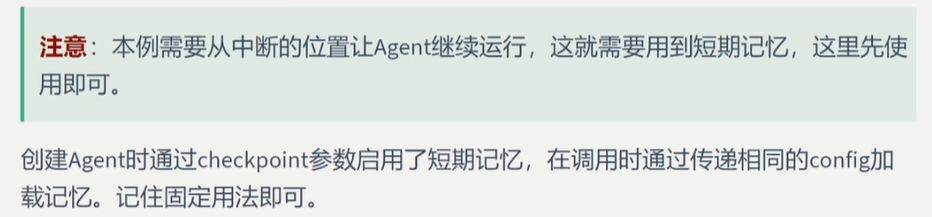

In [1]:

from langchain.agents.middleware import SummarizationMiddleware, HumanInTheLoopMiddleware
from langchain_core.messages import SystemMessage, HumanMessage, AIMessage
from langchain_core.tools import tool
from langchain_openai import ChatOpenAI
from langchain.agents import create_agent
from langgraph.checkpoint.memory import InMemorySaver
from rich import print as rprint
from utils.tool_utils import get_weather2,get_news,read_email_tool,send_email_tool

# 1.初始化模型给
model = ChatOpenAI(
    # model="qwen3-vl:latest",
    # model="483025889/qwen3.5:9b",
    model="gemma4:12b",
    profile={"max_input_tokens": 128_000},
    api_key="sk12345",
    base_url="http://localhost:11434/v1",
)

# 2.创建agent
agent = create_agent(
    model="ollama:483025889/qwen3.5:9b", # agent的大模型和上面中间件的模式必须不一样
    tools=[get_weather2,get_news,read_email_tool,send_email_tool],
    checkpointer=InMemorySaver(),
    middleware=[    # 配置内置中间件
       HumanInTheLoopMiddleware(
             interrupt_on={
                 "get_weather2":True, # 对于不同的工具使用不同的设置
                 "get_news":True,
                 "read_email_tool":False,
                 "send_email_tool":{
                     "allowed_decisions":["approve","reject"],
                     "description":"发送邮件中断了！！！"
                 },
             },
           description_prefix="中断啦!!!"
       ),
    ]

)

msgs = [
    HumanMessage(
        content="请帮我查询今天北京的天气"
                "查询今日新闻"
                "查看ID为：'sk-2131421' 的邮件内容"
                "向15641685664@qq.com发送邮件，标题是'哈哈哈',内容是：'你好啊'"
                "同时做这四件事情"
    ),

]

# 下面这个配置可以确保在同一个会话当中
config={"configurable":{"thread_id":"1"}}

# 3.调用agent
resp = agent.invoke({"messages":msgs},config=config)

rprint(resp)

{
    'messages': [
        HumanMessage(
            content="请帮我查询今天北京的天气查询今日新闻查看ID为：'sk-2131421' 
的邮件内容向15641685664@qq.com发送邮件，标题是'哈哈哈',内容是：'你好啊'同时做这四件事情",
            additional_kwargs={},
            response_metadata={},
            id='c0004319-f79d-40a8-a192-edf35b82acac'
        ),
        AIMessage(
            content='',
            additional_kwargs={},
            response_metadata={
                'model': '483025889/qwen3.5:9b',
                'created_at': '2026-10-15T19:54:16.0265817Z',
                'done': True,
                'done_reason': 'stop',
                'total_duration': 109117440200,
                'load_duration': 9705152200,
                'prompt_eval_count': 528,
                'prompt_eval_duration': 22375832000,
                'eval_count': 358,
                'eval_duration': 77014391000,
                'logprobs': None,
                'model_name': '483025889/qwen3.5:9b',
                'model_provider': 'ollama'
            },
            id='lc_run--01a1411f-8412-72e3-b932-0fd9e2546280-0',
            tool_calls=[
                {
                    'name': 'get_weather2',
                    'args': {'city': '北京', 'if_forecast': True},
                    'id': '989f362e-39e9-4c05-b92f-1571d50c81b3',
                    'type': 'tool_call'
                },
                {
                    'name': 'get_news',
                    'args': {},
                    'id': '51386102-1e4b-492d-aae1-21d88d4fc9ef',
                    'type': 'tool_call'
                },
                {
                    'name': 'read_email_tool',
                    'args': {'email_id': 'sk-2131421'},
                    'id': '2a4597f1-8285-49c8-b2ec-a86dfa70ef2e',
                    'type': 'tool_call'
                },
                {
                    'name': 'send_email_tool',
                    'args': {'recipient': '15641685664@qq.com', 'subject': '哈哈哈', 'body': '你好啊'},
                    'id': '67b82cab-e500-43d9-bf9c-722f3fe8e7c6',
                    'type': 'tool_call'
                }
            ],
            invalid_tool_calls=[],
            usage_metadata={'input_tokens': 528, 'output_tokens': 358, 'total_tokens': 886}
        )
    ],
    '__interrupt__': [
        Interrupt(
            value={
                'action_requests': [
                    {
                        'name': 'get_weather2',
                        'args': {'city': '北京', 'if_forecast': True},
                        'description': "中断啦!!!\n\nTool: get_weather2\nArgs: {'city': '北京', 'if_forecast': 
True}"
                    },
                    {'name': 'get_news', 'args': {}, 'description': '中断啦!!!\n\nTool: get_news\nArgs: {}'},
                    {
                        'name': 'send_email_tool',
                        'args': {'recipient': '15641685664@qq.com', 'subject': '哈哈哈', 'body': '你好啊'},
                        'description': '发送邮件中断了！！！'
                    }
                ],
                'review_configs': [
                    {'action_name': 'get_weather2', 'allowed_decisions': ['approve', 'edit', 'reject']},
                    {'action_name': 'get_news', 'allowed_decisions': ['approve', 'edit', 'reject']},
                    {'action_name': 'send_email_tool', 'allowed_decisions': ['approve', 'reject']}
                ]
            },
            id='e765eb00760bf91c94e2deb976e08628'
        )
    ]
}

## 指明工具调用请求决策
### 执行上面的代码后，agent处于中断状态，现在我们需要让他继续执行，下面的程序不是完整程序，是接着上面的代码继续写的。

In [2]:
# 注意：需要先运行上面的程序然后才能够运行这个程序
from langgraph.types import Command

# 如果有中断，说明进入人在环了
weather_decision={
    "type":"edit",
    "edited_action":{
        "name":"get_weather2",
        "args":{"city":"中国上海","is_forcast":True}
    }
}
news_decision = {
    "type":"approve",
}
send_email_decision = {
    "type":"approve",
}

decisions= {
    "decisions":[]
}

interrupts = resp.get("__interrupt__",[])
action_requests = interrupts[0].value['action_requests']

# 决策的顺序必须和中断的请求顺序一致
for action_request in action_requests:
    if action_request["name"] == "get_weather2":
        decisions["decisions"].append(weather_decision)
    if action_request["name"] == "get_news":
        decisions["decisions"].append(news_decision)
    if action_request["name"] == "send_email_tool":
        decisions["decisions"].append(send_email_decision)
if interrupts:
    # 审批通过
    final_resp = agent.invoke(
        Command(resume=decisions),
        config=config,

    )

    for msg in final_resp["messages"]:
        msg.pretty_print()

>>>执行发送邮件工具了
================================ Human Message =================================

请帮我查询今天北京的天气查询今日新闻查看ID为：'sk-2131421' 的邮件内容向15641685664@qq.com发送邮件，标题是'哈哈哈',内容是：'你好啊'同时做这四件事情
================================== Ai Message ==================================
Tool Calls:
  get_weather2 (989f362e-39e9-4c05-b92f-1571d50c81b3)
 Call ID: 989f362e-39e9-4c05-b92f-1571d50c81b3
  Args:
    city: 中国上海
    is_forcast: True
  get_news (51386102-1e4b-492d-aae1-21d88d4fc9ef)
 Call ID: 51386102-1e4b-492d-aae1-21d88d4fc9ef
  Args:
  read_email_tool (2a4597f1-8285-49c8-b2ec-a86dfa70ef2e)
 Call ID: 2a4597f1-8285-49c8-b2ec-a86dfa70ef2e
  Args:
    email_id: sk-2131421
  send_email_tool (67b82cab-e500-43d9-bf9c-722f3fe8e7c6)
 Call ID: 67b82cab-e500-43d9-bf9c-722f3fe8e7c6
  Args:
    recipient: 15641685664@qq.com
    subject: 哈哈哈
    body: 你好啊
================================= Tool Message =================================
Name: get_weather2

中国上海明天天气不错
================================= Tool Mess